In [1]:
#Los días de cierre 25 de diciembre se excluyen de las métricas. Se agrega una revisión visual de pronósticos por clase de demanda
#imports
from pathlib import Path
from datetime import timedelta
import numpy as np
import pandas as pd
import polars as pl
import plotly.graph_objects as go
from plotly.subplots import make_subplots

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

H, STEP, WINDOWS = 28, 28, 3

df = pl.read_parquet(PROC / "m5_CA_1.parquet")
seg = pl.read_parquet(PROC / "segmentacion_CA_1.parquet")

# Fechas como pd.Timestamp (pandas/statsforecast); en filtros de Polars se usa .date()
last_date = pd.Timestamp(df["date"].max())
test_start = last_date - timedelta(days=H - 1)                 # inicio de la prueba final (no se toca)
first_cutoff = test_start - timedelta(days=H * WINDOWS + 1)    # último día de entrenamiento de la 1ª ventana

dev = df.filter(pl.col("date") < test_start.date())
print("Prueba final (reservada):", test_start.date(), "→", last_date.date())
print("Cortes de backtest esperados:",
      [str((first_cutoff + timedelta(days=STEP * i)).date()) for i in range(WINDOWS)])

Prueba final (reservada): 2016-04-25 → 2016-05-22
Cortes de backtest esperados: ['2016-01-31', '2016-02-28', '2016-03-27']


In [2]:
# Validación de series
chk = (dev.group_by("id")
          .agg(inicio=pl.col("date").min(), fin=pl.col("date").max(), n=pl.len())
          .with_columns(esperado=(pl.col("fin") - pl.col("inicio")).dt.total_days() + 1)
          .with_columns(huecos=pl.col("esperado") - pl.col("n")))

con_huecos = chk.filter(pl.col("huecos") > 0)
print("Series con huecos de fechas:", con_huecos.height)
if con_huecos.height > 0:
    print(con_huecos.sort("huecos", descending=True).head(10))

MIN_HIST = 180  # días mínimos de historia antes del primer corte
limite_inicio = (first_cutoff - timedelta(days=MIN_HIST)).date()
validas = chk.filter((pl.col("inicio") <= limite_inicio) & (pl.col("huecos") == 0))["id"]
print(f"Series válidas: {validas.len()} de {chk.height}")

Y = (dev.filter(pl.col("id").is_in(validas.to_list()))
        .select(unique_id=pl.col("id").cast(pl.Utf8), ds="date", y=pl.col("sales").cast(pl.Float32))
        .to_pandas())
Y["ds"] = pd.to_datetime(Y["ds"])

Series con huecos de fechas: 0
Series válidas: 3041 de 3049


In [3]:
#Backtesting de baselines
import time
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, WindowAverage, CrostonOptimized, TSB, AutoETS

modelos = [
    Naive(),
    SeasonalNaive(season_length=7),
    WindowAverage(window_size=28),
    CrostonOptimized(),
    TSB(alpha_d=0.1, alpha_p=0.1),
    AutoETS(season_length=7),
]

sf = StatsForecast(models=modelos, freq="D", n_jobs=-1)

t0 = time.time()
cv = sf.cross_validation(df=Y, h=H, step_size=STEP, n_windows=WINDOWS)
if "unique_id" not in cv.columns:
    cv = cv.reset_index()
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")

# Recorta pronósticos negativos (ETS puede generarlos) y guarda
MODELOS = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
cv[MODELOS] = cv[MODELOS].clip(lower=0)
cv.to_parquet(PROC / "cv_baselines_CA_1.parquet")

print("Cortes obtenidos:", [str(c.date()) for c in sorted(pd.to_datetime(cv["cutoff"].unique()))])
cv.head()

Tiempo: 7.1 min
Cortes obtenidos: ['2016-01-31', '2016-02-28', '2016-03-27']


,unique_id,ds,cutoff,y,Naive,SeasonalNaive,WindowAverage,CrostonOptimized,TSB,AutoETS
0,FOODS_1_001_CA_1_evaluation,2016-02-01,2016-01-31,0.0,2.0,0.0,0.535714,0.59596,0.749273,0.461583
1,FOODS_1_001_CA_1_evaluation,2016-02-02,2016-01-31,2.0,2.0,1.0,0.535714,0.59596,0.749273,0.446603
2,FOODS_1_001_CA_1_evaluation,2016-02-03,2016-01-31,0.0,2.0,1.0,0.535714,0.59596,0.749273,0.527392
3,FOODS_1_001_CA_1_evaluation,2016-02-04,2016-01-31,3.0,2.0,2.0,0.535714,0.59596,0.749273,0.455073
4,FOODS_1_001_CA_1_evaluation,2016-02-05,2016-01-31,1.0,2.0,1.0,0.535714,0.59596,0.749273,0.735002


In [4]:
# Escala RMSSE: error cuadrático medio del naive de 1 paso en el entrenamiento (antes del primer corte)
train = Y[Y["ds"] <= first_cutoff].sort_values(["unique_id", "ds"])
escala = (train.assign(d2=train.groupby("unique_id")["y"].diff() ** 2)
               .groupby("unique_id")["d2"].mean()
               .rename("escala"))
escala = escala[escala > 0]

# Excluir días de cierre de tienda (25 de diciembre) de la evaluación
cvm = cv.merge(escala, left_on="unique_id", right_index=True, how="inner")
cvm = cvm[~((cvm["ds"].dt.month == 12) & (cvm["ds"].dt.day == 25))]

def calcular_metricas(data, modelos):
    filas = []
    for m in modelos:
        e = data["y"] - data[m]
        por_serie = (data.assign(se=e ** 2)
                         .groupby(["unique_id", "cutoff"])
                         .agg(mse=("se", "mean"), escala=("escala", "first")))
        filas.append({
            "modelo": m,
            "RMSSE": np.sqrt(por_serie["mse"] / por_serie["escala"]).mean(),
            "MAE": e.abs().mean(),
            "Sesgo_%": -e.sum() / data["y"].sum() * 100,   # + = sobrepronóstico, − = subpronóstico
        })
    return pd.DataFrame(filas).sort_values("RMSSE").reset_index(drop=True)

metricas = calcular_metricas(cvm, MODELOS)
metricas.to_csv(ROOT / "reports" / "metricas_baselines_CA_1.csv", index=False)
metricas.round(3)

,modelo,RMSSE,MAE,Sesgo_%
0,AutoETS,0.697,1.087,-1.623
1,WindowAverage,0.701,1.099,-2.624
2,TSB,0.701,1.100,-0.557
3,CrostonOptimized,0.735,1.202,6.571
4,SeasonalNaive,0.912,1.288,-4.303
5,Naive,0.941,1.535,25.847


In [5]:
clases = seg.select(unique_id=pl.col("id").cast(pl.Utf8), sb_class="sb_class", abc="abc").to_pandas()
cvc = cvm.merge(clases, on="unique_id", how="left")

def rmsse_por(data, grupo, modelos):
    res = []
    for m in modelos:
        tmp = (data.assign(se=(data["y"] - data[m]) ** 2)
                   .groupby([grupo, "unique_id", "cutoff"])
                   .agg(mse=("se", "mean"), escala=("escala", "first"))
                   .reset_index())
        tmp["rmsse"] = np.sqrt(tmp["mse"] / tmp["escala"])
        res.append(tmp.groupby(grupo)["rmsse"].mean().rename(m))
    tabla = pd.concat(res, axis=1)
    tabla["n_series"] = data.groupby(grupo)["unique_id"].nunique()
    return tabla

por_clase = rmsse_por(cvc, "sb_class", MODELOS)
por_abc = rmsse_por(cvc, "abc", MODELOS)

display(por_clase.round(3).style.highlight_min(axis=1, subset=MODELOS, color="#c6efce"))
display(por_abc.round(3).style.highlight_min(axis=1, subset=MODELOS, color="#c6efce"))

,Naive,SeasonalNaive,WindowAverage,CrostonOptimized,TSB,AutoETS,n_series
sb_class,,,,,,,
erratic,0.918000,0.809000,0.648000,0.679000,0.651000,0.656000,76
intermittent,0.937000,0.926000,0.706000,0.740000,0.706000,0.702000,2188
lumpy,0.900000,0.859000,0.667000,0.700000,0.664000,0.667000,546
smooth,1.084000,0.942000,0.759000,0.786000,0.764000,0.733000,231


,Naive,SeasonalNaive,WindowAverage,CrostonOptimized,TSB,AutoETS,n_series
abc,,,,,,,
A,1.008000,0.927000,0.728000,0.765000,0.727000,0.717000,1217
B,0.950000,0.937000,0.716000,0.743000,0.717000,0.712000,924
C,0.841000,0.867000,0.650000,0.686000,0.651000,0.654000,900


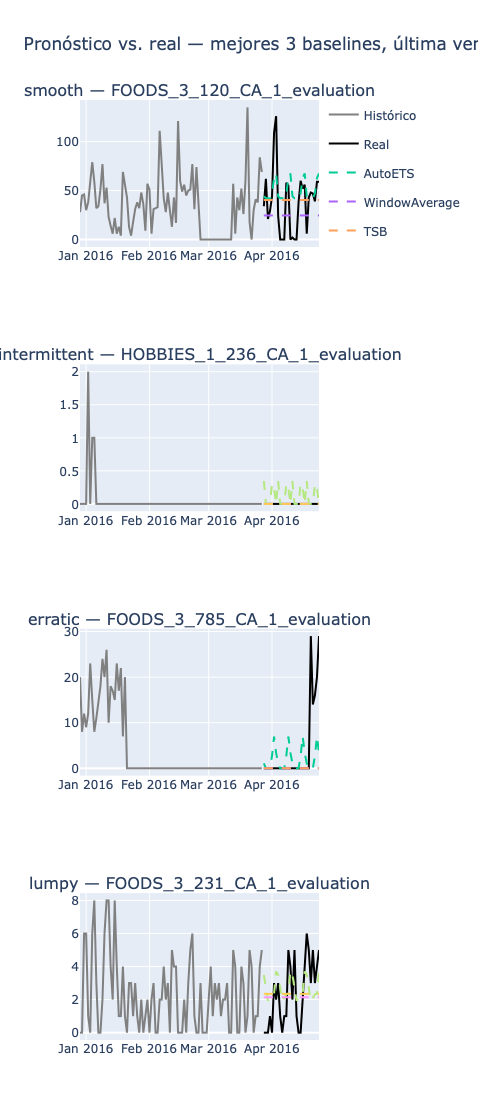

In [6]:
ultimo_corte = pd.Timestamp(cv["cutoff"].max())
top3 = metricas["modelo"].head(3).tolist()

# Producto con mayor ingreso de cada clase
ejemplos = (seg.filter(pl.col("id").cast(pl.Utf8).is_in(Y["unique_id"].unique().tolist()))
               .sort("revenue", descending=True)
               .group_by("sb_class", maintain_order=True).first()
               .select(unique_id=pl.col("id").cast(pl.Utf8), sb_class="sb_class")
               .to_pandas())

fig = make_subplots(rows=len(ejemplos), cols=1, shared_xaxes=False,
                    subplot_titles=[f"{r.sb_class} — {r.unique_id}" for r in ejemplos.itertuples()])

for i, r in enumerate(ejemplos.itertuples(), start=1):
    hist = Y[(Y["unique_id"] == r.unique_id) &
             (Y["ds"] > ultimo_corte - timedelta(days=90)) & (Y["ds"] <= ultimo_corte)]
    pron = cv[(cv["unique_id"] == r.unique_id) & (cv["cutoff"] == ultimo_corte)]
    fig.add_scatter(x=hist["ds"], y=hist["y"], name="Histórico", line=dict(color="gray"),
                    showlegend=(i == 1), row=i, col=1)
    fig.add_scatter(x=pron["ds"], y=pron["y"], name="Real", line=dict(color="black"),
                    showlegend=(i == 1), row=i, col=1)
    for m in top3:
        fig.add_scatter(x=pron["ds"], y=pron[m], name=m, line=dict(dash="dash"),
                        legendgroup=m, showlegend=(i == 1), row=i, col=1)

fig.update_layout(height=280 * len(ejemplos), title="Pronóstico vs. real — mejores 3 baselines, última ventana")
fig.write_html(FIG_DIR / "06_baselines_ejemplos.html")
fig.show()

In [7]:
P_UMBRAL = 1e-4     # probabilidad máxima de que la racha sea azar
MIN_DIAS = 3        # racha mínima para considerar agotado
VENTANA = 56        # días previos para estimar la probabilidad local de cero
P0_MIN = 0.01       # piso para productos que casi nunca tienen ceros

base = (
    dev.sort(["id", "date"])
    .with_columns(cero=pl.col("sales") == 0)
    .with_columns(
        # Probabilidad local de cero: fracción de ceros en los 56 días previos (sin incluir el día actual)
        p0_prev=pl.col("cero").cast(pl.Float64)
                  .rolling_mean(window_size=VENTANA, min_samples=28)
                  .shift(1).over("id"),
        # Ventas acumuladas: 0 mientras el producto no ha tenido su primera venta
        acum=pl.col("sales").cum_sum().over("id"),
        grupo=(pl.col("cero") != pl.col("cero").shift(1).over("id"))
              .fill_null(True).cast(pl.Int32).cum_sum().over("id"),
    )
)

rachas = (
    base.filter(pl.col("cero"))
    .group_by(["id", "grupo"])
    .agg(dias=pl.len(),
         inicio=pl.col("date").min(),
         fin=pl.col("date").max(),
         p0=pl.col("p0_prev").first(),
         pre_lanzamiento=(pl.col("acum").max() == 0))
    .with_columns(p_azar=pl.col("p0").clip(lower_bound=P0_MIN) ** pl.col("dias"))
    .with_columns(
        tipo=pl.when(pl.col("pre_lanzamiento")).then(pl.lit("pre_lanzamiento"))
        .when((pl.col("dias") >= MIN_DIAS) & (pl.col("p_azar") < P_UMBRAL)).then(pl.lit("agotado"))
        .otherwise(pl.lit("normal"))
    )
)

agotados = rachas.filter(pl.col("tipo") == "agotado")
prelanz = rachas.filter(pl.col("tipo") == "pre_lanzamiento")
total = dev.height

print(f"Pre-lanzamiento: {prelanz['dias'].sum():,} días en {prelanz['id'].n_unique():,} productos "
      f"({prelanz['dias'].sum() / total:.1%})")
print(f"Agotados:        {agotados['dias'].sum():,} días en {agotados['id'].n_unique():,} productos "
      f"({agotados['dias'].sum() / total:.1%})")

info = seg.select(["id", "abc", "sb_class"])
for grupo in ["abc", "sb_class"]:
    print(
        agotados.join(info, on="id", how="left")
        .group_by(grupo)
        .agg(productos=pl.col("id").n_unique(), rachas=pl.len(), dias=pl.col("dias").sum())
        .sort(grupo)
    )

# Rachas más largas
print(agotados.sort("dias", descending=True).select(["id", "dias", "inicio", "fin", "p0", "p_azar"]).head(10))

# Guardar para usar en la Fase 2b y la Fase 3
rachas.write_parquet(PROC / "rachas_cero_CA_1.parquet")

Pre-lanzamiento: 6,703 días en 1,912 productos (0.1%)
Agotados:        644,707 días en 2,666 productos (13.7%)
shape: (3, 4)
┌─────┬───────────┬────────┬────────┐
│ abc ┆ productos ┆ rachas ┆ dias   │
│ --- ┆ ---       ┆ ---    ┆ ---    │
│ str ┆ u32       ┆ u32    ┆ u32    │
╞═════╪═══════════╪════════╪════════╡
│ A   ┆ 1123      ┆ 6156   ┆ 262300 │
│ B   ┆ 832       ┆ 3355   ┆ 211059 │
│ C   ┆ 711       ┆ 2015   ┆ 171348 │
└─────┴───────────┴────────┴────────┘
shape: (4, 4)
┌──────────────┬───────────┬────────┬────────┐
│ sb_class     ┆ productos ┆ rachas ┆ dias   │
│ ---          ┆ ---       ┆ ---    ┆ ---    │
│ str          ┆ u32       ┆ u32    ┆ u32    │
╞══════════════╪═══════════╪════════╪════════╡
│ erratic      ┆ 73        ┆ 485    ┆ 8929   │
│ intermittent ┆ 1878      ┆ 7082   ┆ 468952 │
│ lumpy        ┆ 517       ┆ 2957   ┆ 149328 │
│ smooth       ┆ 198       ┆ 1002   ┆ 17498  │
└──────────────┴───────────┴────────┴────────┘
shape: (10, 6)
┌─────────────────────────────────

In [8]:
MIN_DIAS = 3
P_UMBRAL = 1e-4
total = dev.height

def clasificar(r, p0_max, dias_inactivo):
    return r.with_columns(
        tipo=pl.when(pl.col("pre_lanzamiento")).then(pl.lit("pre_lanzamiento"))
        .when(pl.col("dias") >= dias_inactivo).then(pl.lit("inactivo"))
        .when((pl.col("dias") >= MIN_DIAS) & (pl.col("p0") <= p0_max) & (pl.col("p_azar") < P_UMBRAL))
        .then(pl.lit("agotado"))
        .otherwise(pl.lit("normal"))
    )

# --- Sensibilidad: % de días-producto según los parámetros ---
filas = []
for p0_max in [0.3, 0.5, 0.7]:
    for dias_inactivo in [56, 90, 180]:
        c = clasificar(rachas, p0_max, dias_inactivo)
        d = dict(c.group_by("tipo").agg(pl.col("dias").sum()).iter_rows())
        filas.append({"P0_MAX": p0_max, "DIAS_INACTIVO": dias_inactivo,
                      "agotado_%": round(d.get("agotado", 0) / total * 100, 2),
                      "inactivo_%": round(d.get("inactivo", 0) / total * 100, 2)})
print(pl.DataFrame(filas))

# --- Clasificación final con los parámetros base ---
P0_MAX, DIAS_INACTIVO = 0.5, 90
rachas_c = clasificar(rachas, P0_MAX, DIAS_INACTIVO)

resumen_tipo = (rachas_c.group_by("tipo")
                .agg(productos=pl.col("id").n_unique(), rachas=pl.len(), dias=pl.col("dias").sum())
                .with_columns(pct_dias=(pl.col("dias") / total * 100).round(2))
                .sort("dias", descending=True))
print(resumen_tipo)

info = seg.select(["id", "abc", "sb_class"])
for grupo in ["abc", "sb_class"]:
    print(
        rachas_c.filter(pl.col("tipo") == "agotado")
        .join(info, on="id", how="left")
        .group_by(grupo)
        .agg(productos=pl.col("id").n_unique(), rachas=pl.len(), dias=pl.col("dias").sum(),
             mediana_dias=pl.col("dias").median())
        .sort(grupo)
    )

# Control: FOODS_3_090 (agotado crónico) debe aparecer como agotado
print(rachas_c.filter(pl.col("id") == "FOODS_3_090_CA_1_evaluation")
              .filter(pl.col("tipo") != "normal")
              .select(["inicio", "fin", "dias", "p0", "tipo"]).sort("inicio"))

rachas_c.write_parquet(PROC / "rachas_cero_CA_1.parquet")

shape: (9, 4)
┌────────┬───────────────┬───────────┬────────────┐
│ P0_MAX ┆ DIAS_INACTIVO ┆ agotado_% ┆ inactivo_% │
│ ---    ┆ ---           ┆ ---       ┆ ---        │
│ f64    ┆ i64           ┆ f64       ┆ f64        │
╞════════╪═══════════════╪═══════════╪════════════╡
│ 0.3    ┆ 56            ┆ 0.9       ┆ 12.48      │
│ 0.3    ┆ 90            ┆ 1.42      ┆ 9.92       │
│ 0.3    ┆ 180           ┆ 2.3       ┆ 4.73       │
│ 0.5    ┆ 56            ┆ 1.73      ┆ 12.48      │
│ 0.5    ┆ 90            ┆ 2.69      ┆ 9.92       │
│ 0.5    ┆ 180           ┆ 4.57      ┆ 4.73       │
│ 0.7    ┆ 56            ┆ 2.58      ┆ 12.48      │
│ 0.7    ┆ 90            ┆ 4.05      ┆ 9.92       │
│ 0.7    ┆ 180           ┆ 7.15      ┆ 4.73       │
└────────┴───────────────┴───────────┴────────────┘
shape: (4, 5)
┌─────────────────┬───────────┬────────┬─────────┬──────────┐
│ tipo            ┆ productos ┆ rachas ┆ dias    ┆ pct_dias │
│ ---             ┆ ---       ┆ ---    ┆ ---     ┆ ---      │
│ str 

In [9]:
dias_marcados = (
    rachas_c.filter(pl.col("tipo") != "normal")
    .with_columns(date=pl.date_ranges("inicio", "fin"))
    .explode("date")
    .select(id=pl.col("id").cast(pl.Utf8), date="date", tipo="tipo")
)

mascara = (
    dev.select(id=pl.col("id").cast(pl.Utf8), date="date")
    .join(dias_marcados, on=["id", "date"], how="left")
    .with_columns(tipo=pl.col("tipo").fill_null("normal"))
    .with_columns(excluir=pl.col("tipo") != "normal")
)

print(mascara.group_by("tipo").agg(dias=pl.len()).sort("dias", descending=True))
print(f"Días excluidos: {mascara['excluir'].sum():,} ({mascara['excluir'].mean():.1%})")

mascara.write_parquet(PROC / "mascara_CA_1.parquet")

shape: (4, 2)
┌─────────────────┬─────────┐
│ tipo            ┆ dias    │
│ ---             ┆ ---     │
│ str             ┆ u32     │
╞═════════════════╪═════════╡
│ normal          ┆ 4103296 │
│ inactivo        ┆ 466480  │
│ agotado         ┆ 126416  │
│ pre_lanzamiento ┆ 6703    │
└─────────────────┴─────────┘
Días excluidos: 599,599 (12.7%)


In [10]:
masc = (mascara.select(unique_id="id", ds="date", excluir="excluir").to_pandas())
masc["ds"] = pd.to_datetime(masc["ds"])

cvm_m = cvm.merge(masc, on=["unique_id", "ds"], how="left")
cvm_m["excluir"] = cvm_m["excluir"].fillna(False).astype(bool)
print(f"Filas de evaluación excluidas: {cvm_m['excluir'].mean():.1%}")
cvm_m = cvm_m[~cvm_m["excluir"]]

metricas_m = calcular_metricas(cvm_m, MODELOS)
comparacion = (metricas.merge(metricas_m, on="modelo", suffixes=("_todo", "_limpio"))
               [["modelo", "RMSSE_todo", "RMSSE_limpio", "Sesgo_%_todo", "Sesgo_%_limpio",
                 "MAE_todo", "MAE_limpio"]]
               .sort_values("RMSSE_limpio"))
comparacion.to_csv(ROOT / "reports" / "metricas_baselines_limpio_CA_1.csv", index=False)
display(comparacion.round(3))

cvc_m = cvm_m.merge(clases, on="unique_id", how="left")
display(rmsse_por(cvc_m, "sb_class", MODELOS).round(3)
        .style.highlight_min(axis=1, subset=MODELOS, color="#c6efce"))

Filas de evaluación excluidas: 8.1%


,modelo,RMSSE_todo,RMSSE_limpio,Sesgo_%_todo,Sesgo_%_limpio,MAE_todo,MAE_limpio
0,AutoETS,0.697,0.740,-1.623,-4.746,1.087,1.133
3,CrostonOptimized,0.735,0.746,6.571,-2.476,1.202,1.164
1,WindowAverage,0.701,0.748,-2.624,-5.648,1.099,1.148
2,TSB,0.701,0.749,-0.557,-3.316,1.100,1.154
4,SeasonalNaive,0.912,0.973,-4.303,-6.706,1.288,1.364
5,Naive,0.941,1.004,25.847,22.746,1.535,1.621


,Naive,SeasonalNaive,WindowAverage,CrostonOptimized,TSB,AutoETS,n_series
sb_class,,,,,,,
erratic,0.936000,0.825000,0.658000,0.673000,0.662000,0.662000,76
intermittent,1.003000,0.991000,0.756000,0.754000,0.757000,0.748000,2140
lumpy,0.972000,0.928000,0.720000,0.715000,0.719000,0.716000,538
smooth,1.101000,0.958000,0.769000,0.776000,0.775000,0.742000,231
